# 04. 명시 vs 암묵 선호: LLM은 대화 속에 은근히 드러난 선호를 쓰는가 (Study 4)

**질문**: 멀티턴 대화에서 사용자가 선호를 직접 말하지 않고 은근히 드러내기만 하면, LLM은 그 선호를 얼마나 반영하는가? 그게 단순한 표면 유사도(임베딩)보다 나은가?

**데이터**: PersonaMem-v2 (arXiv 2512.06688, CC BY 4.0) 벤치마크에서 800문항, persona 195명.
한 문항 = 질문 1개 + 답변 4개(1개만 그 사용자의 선호에 맞음). 질문 앞의 대화만 조건별로 다르다.

| 조건 | 질문 앞에 오는 것 |
|---|---|
| none | 없음 (답변만으로 얼마나 맞히는지) |
| explicit | "A quick note about me: {선호}." |
| implicit | 선호를 은근히 드러내는 실제 대화 (PersonaMem-v2 snippet) |
| explicit_far / implicit_far | 위 + 무관한 대화 2턴 |

**측정**: 답변 4개를 A–D로 보여주고 고르게 한다. 위치 편향을 없애려고 4번 돌려가며 보여주고 로그확률을 평균. 우연 수준 0.25.
**기준선**: mpnet 임베딩으로 사용자 발화와 가장 비슷한 답변을 고르기.
**검정**: persona 단위 paired bootstrap (2,000회).

모델: Qwen2.5-7B-Instruct, Llama-3.1-8B-Instruct (GPU), Qwen2.5-1.5B (Mac 파일럿 40문항).

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src/implicit"))
from analyze import acc, boot, mc_scores

RUN = ROOT / "runs/implicit"
FIG = ROOT / "docs/figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = {"qwen7b": "Qwen2.5-7B", "llama8b": "Llama-3.1-8B"}
CONDS = ["none", "explicit", "implicit", "explicit_far", "implicit_far"]

items = {it["item"]: it for it in map(json.loads, open(RUN / "items.jsonl"))}
eb = json.load(open(RUN / "embed_baseline.json"))["per_item"]
epos = {iid: k for k, iid in enumerate(eb["item"])}

def load(run):
    meta = json.load(open(RUN / run / "meta.json"))
    A = acc(mc_scores(np.load(RUN / run / "MC.npy")))
    its = [items[i] for i in meta["item_ids"]]
    df = pd.DataFrame(A, columns=meta["conds"])
    df["persona"] = [it["persona"] for it in its]
    df["pref_type"] = [it["pref_type"] for it in its]
    for c in ["explicit", "implicit", "explicit_far", "implicit_far"]:
        df[f"emb_{c}"] = [eb[c][epos[it["item"]]] for it in its]
    return df

D = {m: load(m) for m in MODELS}
{m: len(d) for m, d in D.items()}

{'qwen7b': 800, 'llama8b': 800}

## 1. 조건별 정답률

In [2]:
tab = pd.DataFrame({MODELS[m]: d[CONDS].mean() for m, d in D.items()}).T
tab.loc["embedding (mpnet)"] = [np.nan] + [D["qwen7b"][f"emb_{c}"].mean() for c in CONDS[1:]]
tab.round(3)

,none,explicit,implicit,explicit_far,implicit_far
Qwen2.5-7B,0.230,0.916,0.512,0.829,0.408
Llama-3.1-8B,0.272,0.962,0.735,0.960,0.599
embedding (mpnet),NaN,0.870,0.544,0.498,0.446


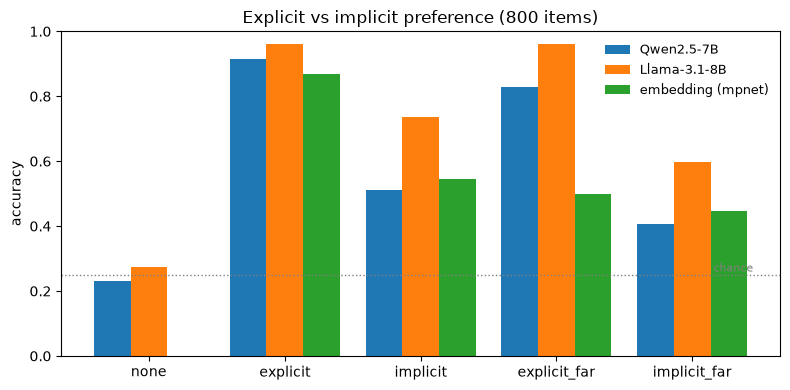

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(CONDS)); w = 0.27
for k, (name, row) in enumerate(tab.iterrows()):
    ax.bar(x + (k - 1) * w, row.values, w, label=name)
ax.axhline(0.25, ls=":", c="gray", lw=1); ax.text(4.45, 0.26, "chance", color="gray", fontsize=8, ha="right")
ax.set_xticks(x, CONDS); ax.set_ylim(0, 1); ax.set_ylabel("accuracy"); ax.legend(frameon=False, fontsize=9)
ax.set_title("Explicit vs implicit preference (800 items)")
plt.tight_layout(); plt.savefig(FIG / "study4_accuracy.png", dpi=150); plt.show()

## 2. 격차 검정 (persona 단위 bootstrap)

In [4]:
pairs = [("explicit", "implicit"), ("implicit", "none"), ("explicit", "explicit_far"), ("implicit", "implicit_far")]
rows = []
for m, d in D.items():
    g = d.persona.values
    for x_, y_ in pairs:
        b = boot(d[x_].values, d[y_].values, g); rows.append([MODELS[m], f"{x_} − {y_}", b["delta"], *b["ci"], b["p"]])
    for c in ["implicit", "implicit_far"]:
        b = boot(d[c].values, d[f"emb_{c}"].values.astype(float), g)
        rows.append([MODELS[m], f"{c}: LLM − embedding", b["delta"], *b["ci"], b["p"]])
pd.DataFrame(rows, columns=["model", "comparison", "delta", "ci_lo", "ci_hi", "p"])

,model,comparison,delta,ci_lo,ci_hi,p
0,Qwen2.5-7B,explicit − implicit,0.4038,0.3652,0.4411,0.0005
1,Qwen2.5-7B,implicit − none,0.2825,0.2485,0.3168,0.0005
2,Qwen2.5-7B,explicit − explicit_far,0.0875,0.0653,0.1117,0.0005
3,Qwen2.5-7B,implicit − implicit_far,0.1050,0.0809,0.1287,0.0005
4,Qwen2.5-7B,implicit: LLM − embedding,-0.0312,-0.0785,0.0162,0.2140
5,Qwen2.5-7B,implicit_far: LLM − embedding,-0.0388,-0.0839,0.0076,0.1190
6,Llama-3.1-8B,explicit − implicit,0.2275,0.1967,0.2600,0.0005
7,Llama-3.1-8B,implicit − none,0.4625,0.4248,0.4987,0.0005
8,Llama-3.1-8B,explicit − explicit_far,0.0025,-0.0061,0.0104,0.6780
9,Llama-3.1-8B,implicit − implicit_far,0.1362,0.1095,0.1652,0.0005


## 3. 표면 유사도를 넘어서는가

임베딩이 **틀리는** 문항(표면 유사도로는 못 맞히는 문항)에서 LLM 정답률. 여기서도 높으면 단순히 비슷한 답을 고른 게 아니라 추론한 것이다.

In [5]:
rows = []
for m, d in D.items():
    for c in ["explicit", "implicit", "implicit_far"]:
        hard = d[f"emb_{c}"] == 0
        rows.append([MODELS[m], c, hard.sum(), d.loc[hard, c].mean(), d.loc[~hard, c].mean()])
hard_df = pd.DataFrame(rows, columns=["model", "cond", "n_embed_wrong", "llm_on_embed_wrong", "llm_on_embed_right"])
hard_df.round(3)

,model,cond,n_embed_wrong,llm_on_embed_wrong,llm_on_embed_right
0,Qwen2.5-7B,explicit,104,0.712,0.947
1,Qwen2.5-7B,implicit,365,0.458,0.559
2,Qwen2.5-7B,implicit_far,443,0.372,0.451
3,Llama-3.1-8B,explicit,104,0.798,0.987
4,Llama-3.1-8B,implicit,365,0.655,0.802
5,Llama-3.1-8B,implicit_far,443,0.546,0.664


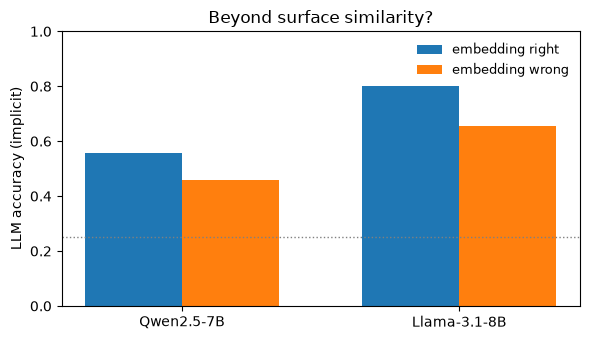

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sub = hard_df[hard_df.cond == "implicit"]
x = np.arange(len(sub)); w = 0.35
ax.bar(x - w/2, sub.llm_on_embed_right, w, label="embedding right")
ax.bar(x + w/2, sub.llm_on_embed_wrong, w, label="embedding wrong")
ax.axhline(0.25, ls=":", c="gray", lw=1)
ax.set_xticks(x, sub.model); ax.set_ylim(0, 1); ax.set_ylabel("LLM accuracy (implicit)")
ax.legend(frameon=False, fontsize=9); ax.set_title("Beyond surface similarity?")
plt.tight_layout(); plt.savefig(FIG / "study4_beyond_embedding.png", dpi=150); plt.show()

## 4. 대화 거리: 무관한 대화가 끼면 얼마나 잊는가

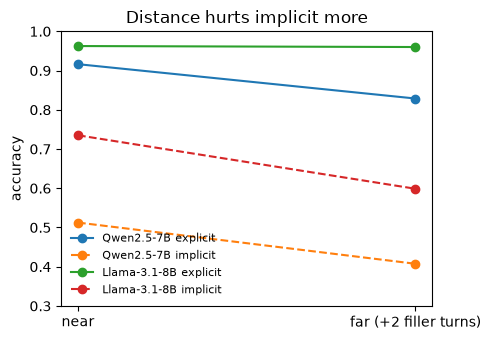

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.5))
for m, d in D.items():
    for kind, ls in [("explicit", "-"), ("implicit", "--")]:
        ax.plot([0, 1], [d[kind].mean(), d[f"{kind}_far"].mean()], ls, marker="o", label=f"{MODELS[m]} {kind}")
ax.set_xticks([0, 1], ["near", "far (+2 filler turns)"]); ax.set_ylim(0.3, 1); ax.set_ylabel("accuracy")
ax.legend(frameon=False, fontsize=8); ax.set_title("Distance hurts implicit more")
plt.tight_layout(); plt.savefig(FIG / "study4_distance.png", dpi=150); plt.show()

## 5. 어떤 선호가 사라지는가: 선호 유형

In [8]:
bt = pd.concat({MODELS[m]: d.groupby("pref_type")[["none", "explicit", "implicit"]].mean() for m, d in D.items()})
bt["n"] = pd.concat({MODELS[m]: d.groupby("pref_type").size() for m, d in D.items()})
bt.round(3)

none  explicit  implicit    n
             pref_type                                              
Qwen2.5-7B   anti_stereotypical_pref  0.199     0.925     0.469  307
             neutral_preferences      0.250     0.890     0.523  300
             stereotypical_pref       0.249     0.943     0.565  193
Llama-3.1-8B anti_stereotypical_pref  0.270     0.971     0.707  307
             neutral_preferences      0.257     0.943     0.720  300
             stereotypical_pref       0.301     0.979     0.803  193

## 6. 파일럿 (Qwen2.5-1.5B, Mac, 40문항) 비교

In [9]:
p = json.load(open(RUN / "pilot15/results_mc.json"))
pd.Series(p["accuracy"]).round(3)

none               0.275
explicit           0.825
implicit           0.550
implicit_attr      0.575
implicit_recall    0.575
dtype: float64

## 7. 모델 크기: 규모 문제인가, 계열 문제인가 (Study 4b)

`gpu_session_study4_scale.sh` 결과가 `runs/implicit/` 아래에 있으면 자동으로 그린다. Qwen 1.5B/3B/7B/14B, Llama 1B/3B/8B.

In [10]:
SIZES = {"qwen1_5b": ("Qwen", 1.5), "qwen3b": ("Qwen", 3), "qwen7b": ("Qwen", 7), "qwen14b": ("Qwen", 14),
         "llama1b": ("Llama", 1), "llama3b": ("Llama", 3), "llama8b": ("Llama", 8)}
rows = []
for run, (fam, b) in SIZES.items():
    f = RUN / run / "results_mc.json"
    if f.exists():
        r = json.load(open(f))
        rows.append({"family": fam, "params_B": b, **r["accuracy"],
                     "implicit_minus_embed": r["vs_embedding"]["implicit"]["llm_minus_embed"]["delta"]})
scale = pd.DataFrame(rows).sort_values(["family", "params_B"])
scale.round(3)

,family,params_B,none,explicit,implicit,explicit_far,implicit_far,implicit_minus_embed
1,Llama,8,0.272,0.962,0.735,0.960,0.599,0.191
0,Qwen,7,0.230,0.916,0.512,0.829,0.408,-0.031


In [11]:
if scale.family.nunique() and len(scale) > 2:
    fig, ax = plt.subplots(figsize=(6, 4))
    for fam, d in scale.groupby("family"):
        ax.plot(d.params_B, d.explicit, "-o", label=f"{fam} explicit")
        ax.plot(d.params_B, d.implicit, "--o", label=f"{fam} implicit")
    ax.axhline(D["qwen7b"]["emb_implicit"].mean(), c="gray", ls=":", lw=1); ax.text(1, 0.555, "embedding (implicit)", color="gray", fontsize=8)
    ax.set_xscale("log"); ax.set_xticks([1, 3, 8, 14], ["1B", "3B", "8B", "14B"]); ax.set_ylim(0.2, 1)
    ax.set_xlabel("parameters"); ax.set_ylabel("accuracy"); ax.legend(frameon=False, fontsize=8)
    ax.set_title("Implicit preference use vs model size")
    plt.tight_layout(); plt.savefig(FIG / "study4_scale.png", dpi=150); plt.show()
else:
    print("scale-sweep results not downloaded yet")

scale-sweep results not downloaded yet


## 결론

1. **명시적인 선호는 모든 모델이 반영한다** (0.92–0.96). **은근히 드러난 선호는 덜 반영한다**: 격차는 Qwen-7B +0.40, Llama-8B +0.23이고 둘 다 유의하다.
2. **모델마다 다르다.** Qwen-7B는 암묵 조건에서 임베딩 기준선과 차이가 없다(−0.03, 유의하지 않음). Llama-8B는 임베딩보다 +0.19 높고, 임베딩이 틀리는 문항에서도 0.65를 맞힌다. 즉 Llama는 추론하고, Qwen은 표면 유사도 수준에 머문다.
3. **암묵 선호는 거리에 약하다.** 무관한 대화 2턴이 끼면 암묵 조건은 0.11–0.14 떨어지고, 명시 조건은 거의 그대로다(Llama 0.00, Qwen 0.09).
4. **예상 가능한 선호를 더 잘 잡는다.** 암묵 조건에서 stereotypical 선호가 anti-stereotypical보다 약 0.09 높다(두 모델 모두).

**한계**: 정해진 답변 4개 중 고르기만 측정했다(직접 쓴 답변의 품질은 아님). 모델 2개, 데이터셋 1개. 왜 모델마다 다른지(학습 데이터, 크기 등)는 이 실험으로 알 수 없다.